# AML 05 — Integrated Evaluation

This notebook combines the completed building, floor, and coordinate prediction outputs. It checks that all three tasks use the same validation rows and source split, recomputes reported metrics from predictions, performs hierarchical error analysis, and exports consolidated tables and figures.

The internal validation split and supplied heldout validation split are reported separately. Joins use `(SOURCE_PARTITION, ROW_ID)` because `ROW_ID` restarts in each original source file. Coordinate error is reported in the units declared by the coordinate-regression pipeline (`EPSG:3857` projected metres); it is not interpreted as scale-corrected ground distance. No models are retrained here.

**Project:** Project 9 — Indoor Location Prediction Using Wi-Fi Signals  
**Phase:** AML (Phase 1)  
**Pipeline:** Integrated AML Evaluation

## Notebook navigation

- [1. Environment and configuration](#---)
- [2. Input artifacts and split validation](#-----)
- [3. Join predictions and validate provenance](#-----)
- [4. Recompute task metrics and compare with task summaries](#------w--)
- [5. Hierarchical error analysis](#---)
- [6. Consolidated confusion matrices and visualizations](#-----)
- [7. Export integrated submission artifacts](#----)
- [8. Interpretation and scope](#---)
- [Conclusion](#)
- [Next Steps](#-)


## 1. Environment and configuration

Imports, reproducibility settings, and repository-relative paths are initialized in the code cells below. This notebook is designed to run independently from a fresh kernel.


**Cell purpose:** Imports project packages and resolves the repository root.


In [1]:
from pathlib import Path
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, confusion_matrix

# Work from the repository root; this also supports launching Jupyter from the notebook folder.
CANDIDATE_ROOTS = [Path.cwd(), Path.cwd().parent]
ROOT = next((p.resolve() for p in CANDIDATE_ROOTS if (p / 'data/processed').is_dir() and (p / 'Machine Learning Pipeline').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate repository root containing data/processed and Machine Learning Pipeline.')
PROCESSED = ROOT / 'data' / 'processed'
TABLES = ROOT / 'data' / 'tables'
FIGURES = ROOT / 'data' / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print(f'Repository: {ROOT}')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__}')

Repository: /Users/Krishiv/Desktop/Signal2Space
Python 3.14.2 | pandas 3.0.6 | NumPy 2.5.4


## 2. Input artifacts and split validation

Expected files are the canonical processed feature tables from the preprocessing pipeline, row-level predictions from classification and regression notebooks, and their metric summaries. Legacy files are not read. The feature tables are loaded with only key and target columns needed for validation.

**Cell purpose:** Defines required canonical feature, prediction, and metric inputs.


In [2]:
FILES = {
    'internal_source': PROCESSED / 'aml_internal_validation_features.csv',
    'heldout_source': PROCESSED / 'aml_heldout_validation_features.csv',
    'building_internal': TABLES / 'ml_02_building_internal_validation_predictions.csv',
    'building_heldout': TABLES / 'ml_02_building_heldout_predictions.csv',
    'building_metrics': TABLES / 'ml_02_building_metrics.csv',
    'floor_internal': TABLES / 'ml_03_floor_internal_validation_predictions.csv',
    'floor_heldout': TABLES / 'ml_03_floor_heldout_predictions.csv',
    'floor_metrics': TABLES / 'ml_03_floor_metrics.csv',
    'coordinate_internal': TABLES / 'ml_04_coordinate_internal_validation_predictions.csv',
    'coordinate_heldout': TABLES / 'ml_04_coordinate_heldout_predictions.csv',
    'coordinate_metrics': TABLES / 'ml_04_coordinate_metrics.csv',
}
missing_files = [str(path.relative_to(ROOT)) for path in FILES.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError('Required integration inputs are missing: ' + ', '.join(missing_files))

KEY = ['SOURCE_PARTITION', 'ROW_ID']
TARGET_COLS = KEY + ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']
sources = {
    'internal_validation': pd.read_csv(FILES['internal_source'], usecols=TARGET_COLS),
    'heldout_validation': pd.read_csv(FILES['heldout_source'], usecols=TARGET_COLS),
}
artifacts = {
    'building_internal': pd.read_csv(FILES['building_internal']),
    'building_heldout': pd.read_csv(FILES['building_heldout']),
    'floor_internal': pd.read_csv(FILES['floor_internal']),
    'floor_heldout': pd.read_csv(FILES['floor_heldout']),
    'coordinate_internal': pd.read_csv(FILES['coordinate_internal']),
    'coordinate_heldout': pd.read_csv(FILES['coordinate_heldout']),
}
team_metrics = {
    'building': pd.read_csv(FILES['building_metrics']),
    'floor': pd.read_csv(FILES['floor_metrics']),
    'coordinate': pd.read_csv(FILES['coordinate_metrics']),
}
for split, src in sources.items():
    assert not src[KEY].isna().any().any(), f'{split}: null key values'
    assert not src.duplicated(KEY).any(), f'{split}: duplicate source keys'
    expected_partition = 'trainingData' if split == 'internal_validation' else 'validationData'
    assert set(src['SOURCE_PARTITION']) == {expected_partition}, (split, src['SOURCE_PARTITION'].unique())
    print(f'{split}: {len(src):,} rows; source partition={expected_partition}')

internal_validation: 3,852 rows; source partition=trainingData
heldout_validation: 1,111 rows; source partition=validationData


## 3. Join predictions and validate provenance

Each task prediction file is checked for unique composite keys, exact row coverage, matching true labels/coordinates, and matching split membership. This prevents accidental many-to-many joins and verifies that the task outputs align with the canonical split artifacts.

**Cell purpose:** Defines row-key checks for missing, duplicate, or unmatched predictions.


In [3]:
def assert_unique_keys(df, name):
    missing = set(KEY) - set(df.columns)
    assert not missing, f'{name}: missing key columns {missing}'
    assert not df[KEY].isna().any().any(), f'{name}: null key values'
    assert not df.duplicated(KEY).any(), f'{name}: duplicate composite keys'

def validate_key_coverage(pred, source, name):
    assert_unique_keys(pred, name)
    left = set(map(tuple, pred[KEY].itertuples(index=False, name=None)))
    right = set(map(tuple, source[KEY].itertuples(index=False, name=None)))
    assert left == right, f'{name}: prediction/source key mismatch (missing={len(right-left)}, extra={len(left-right)})'



**Cell purpose:** Validates task prediction keys and true targets, then joins by source and row ID.


In [4]:
def integrate_split(split, suffix):
    source = sources[split].copy()
    b = artifacts[f'building_{suffix}'].copy()
    f = artifacts[f'floor_{suffix}'].copy()
    c = artifacts[f'coordinate_{suffix}'].copy()
    for part, name in [(b, 'building'), (f, 'floor'), (c, 'coordinate')]:
        validate_key_coverage(part, source, f'{split} {name}')
    # Validate source targets before merging.
    check = source[KEY + ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']]
    bcheck = b.merge(check[KEY + ['BUILDINGID']], on=KEY, validate='one_to_one')
    fcheck = f.merge(check[KEY + ['FLOOR']], on=KEY, validate='one_to_one')
    ccheck = c.merge(check[KEY + ['LONGITUDE', 'LATITUDE']], on=KEY, validate='one_to_one')
    assert np.array_equal(bcheck['BUILDINGID_TRUE'].to_numpy(), bcheck['BUILDINGID'].to_numpy()), f'{split}: building true labels differ from source'
    assert np.array_equal(fcheck['FLOOR_TRUE'].to_numpy(), fcheck['FLOOR'].to_numpy()), f'{split}: floor true labels differ from source'
    assert np.allclose(ccheck['LONGITUDE_TRUE'], ccheck['LONGITUDE'], rtol=0, atol=1e-9), f'{split}: longitude truth differs from source'
    assert np.allclose(ccheck['LATITUDE_TRUE'], ccheck['LATITUDE'], rtol=0, atol=1e-9), f'{split}: latitude truth differs from source'
    assert {'BUILDINGID_PRED', 'BUILDINGID_TRUE'} <= set(b.columns)
    assert {'FLOOR_PRED', 'FLOOR_TRUE'} <= set(f.columns)
    assert {'LONGITUDE_PRED', 'LATITUDE_PRED', 'LONGITUDE_TRUE', 'LATITUDE_TRUE', 'EUCLIDEAN_ERROR'} <= set(c.columns)
    if 'COORDINATE_CRS' in c:
        assert set(c['COORDINATE_CRS'].dropna().astype(str)) == {'EPSG:3857'}
    if 'COORDINATE_UNIT' in c:
        assert set(c['COORDINATE_UNIT'].dropna().astype(str)) == {'metre'}
    out = source.merge(b, on=KEY, validate='one_to_one', suffixes=('', '_BUILDING'))
    out = out.merge(f, on=KEY, validate='one_to_one', suffixes=('', '_FLOOR'))
    out = out.merge(c, on=KEY, validate='one_to_one', suffixes=('', '_COORDINATE'))
    assert len(out) == len(source)
    return out



**Cell purpose:** Integrates internal-validation and held-out predictions across all tasks.


In [5]:
integrated = {
    'internal_validation': integrate_split('internal_validation', 'internal'),
    'heldout_validation': integrate_split('heldout_validation', 'heldout'),
}
for split, df in integrated.items():
    print(f'{split}: integrated {len(df):,} rows across all three tasks')

internal_validation: integrated 3,852 rows across all three tasks
heldout_validation: integrated 1,111 rows across all three tasks


## 4. Recompute task metrics and compare with task summaries

The model score summary uses the tuned model rows recorded by each member. This notebook independently recalculates accuracy, macro F1, axis MAE, and mean/median Euclidean coordinate error from the row-level artifacts. The checks fail if the exported summary and predictions disagree.

**Cell purpose:** Defines independent metric recalculation for classification and coordinate predictions.


In [6]:
def metric_row(task, split, df):
    source_split = 'internal_validation' if split == 'internal_validation' else 'heldout_validation'
    if task == 'building':
        truth, pred = df['BUILDINGID_TRUE'], df['BUILDINGID_PRED']
        return {'split': split, 'task': task, 'model_config': 'RandomForestClassifier; ' + tuned_config(team_metrics[task], source_split),
                'accuracy': accuracy_score(truth, pred), 'macro_f1': f1_score(truth, pred, average='macro'),
                'n_rows': len(df), 'coordinate_unit': ''}
    if task == 'floor':
        truth, pred = df['FLOOR_TRUE'], df['FLOOR_PRED']
        return {'split': split, 'task': task, 'model_config': 'RandomForestClassifier; ' + tuned_config(team_metrics[task], source_split),
                'accuracy': accuracy_score(truth, pred), 'macro_f1': f1_score(truth, pred, average='macro'),
                'n_rows': len(df), 'coordinate_unit': ''}
    dx = df['LONGITUDE_PRED'].to_numpy() - df['LONGITUDE_TRUE'].to_numpy()
    dy = df['LATITUDE_PRED'].to_numpy() - df['LATITUDE_TRUE'].to_numpy()
    euclidean = np.hypot(dx, dy)
    return {'split': split, 'task': task, 'model_config': tuned_config(team_metrics[task], source_split),
            'mae_longitude': mean_absolute_error(df['LONGITUDE_TRUE'], df['LONGITUDE_PRED']),
            'mae_latitude': mean_absolute_error(df['LATITUDE_TRUE'], df['LATITUDE_PRED']),
            'mean_euclidean_error': float(np.mean(euclidean)), 'median_euclidean_error': float(np.median(euclidean)),
            'n_rows': len(df), 'coordinate_unit': str(df['COORDINATE_UNIT'].iloc[0]) if 'COORDINATE_UNIT' in df else 'coordinate units'}

def tuned_config(table, split):
    row = table.loc[(table['split'] == split) & (table['model_config'] == 'tuned')]
    assert len(row) == 1, f'Expected one tuned {split} row, found {len(row)}'
    row = row.iloc[0]
    fields = [c for c in ['model_family', 'n_estimators', 'max_depth', 'min_samples_leaf', 'max_features'] if c in row.index]
    return '; '.join(f'{c}={"None" if pd.isna(row[c]) else row[c]}' for c in fields)



**Cell purpose:** Recomputes task metrics and compares them with task-level exports.


In [7]:
metric_records = []
for split, df in integrated.items():
    metric_records.extend(metric_row(task, split, df) for task in ['building', 'floor', 'coordinate'])
summary_metrics = pd.DataFrame(metric_records)



**Cell purpose:** Checks recomputed metrics and row counts against recorded summaries.


In [8]:
def check_metric(task, split, metric_name, actual, source_col):
    tab = team_metrics[task]
    row = tab.loc[(tab['split'] == split) & (tab['model_config'] == 'tuned')]
    assert len(row) == 1, f'{task} metrics: expected one tuned row for {split}'
    expected = float(row.iloc[0][source_col])
    assert np.isclose(actual, expected, rtol=0, atol=1e-8), f'{task} {split} {metric_name}: recomputed={actual}, recorded={expected}'

for split, df in integrated.items():
    for task in ['building', 'floor']:
        m = summary_metrics.query('split == @split and task == @task').iloc[0]
        check_metric(task, 'internal_validation' if split == 'internal_validation' else 'heldout_validation', 'accuracy', m['accuracy'], 'accuracy')
        check_metric(task, 'internal_validation' if split == 'internal_validation' else 'heldout_validation', 'macro_f1', m['macro_f1'], 'macro_f1')
        recorded_split = 'internal_validation' if split == 'internal_validation' else 'heldout_validation'
        metrics_table = team_metrics[task]
        rec = metrics_table.loc[(metrics_table['split'] == recorded_split) & (metrics_table['model_config'] == 'tuned')].iloc[0]
        assert int(rec['n_rows']) == len(df), f'{task} {split}: row count differs from metric summary'
    m = summary_metrics.query('split == @split and task == "coordinate"').iloc[0]
    rec_split = 'internal_validation' if split == 'internal_validation' else 'heldout_validation'
    check_metric('coordinate', rec_split, 'longitude MAE', m['mae_longitude'], 'mae_LONGITUDE_coordinate_units')
    check_metric('coordinate', rec_split, 'latitude MAE', m['mae_latitude'], 'mae_LATITUDE_coordinate_units')
    check_metric('coordinate', rec_split, 'mean Euclidean error', m['mean_euclidean_error'], 'mean_euclidean_error_coordinate_units')
    assert int(team_metrics['coordinate'].loc[(team_metrics['coordinate']['split'] == rec_split) & (team_metrics['coordinate']['model_config'] == 'tuned'), 'n_rows'].iloc[0]) == len(df)

summary_metrics

,split,task,model_config,accuracy,macro_f1,n_rows,coordinate_unit,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error
0,internal_validation,building,RandomForestClassifier; n_estimators=100; max_...,0.999481,0.999497,3852,,NaN,NaN,NaN,NaN
1,internal_validation,floor,RandomForestClassifier; n_estimators=150; max_...,0.964174,0.967825,3852,,NaN,NaN,NaN,NaN
2,internal_validation,coordinate,model_family=RandomForestRegressor; n_estimato...,NaN,NaN,3852,metre,5.914234,5.060706,8.578616,6.306672
3,heldout_validation,building,RandomForestClassifier; n_estimators=100; max_...,0.997300,0.997126,1111,,NaN,NaN,NaN,NaN
4,heldout_validation,floor,RandomForestClassifier; n_estimators=150; max_...,0.889289,0.872655,1111,,NaN,NaN,NaN,NaN
5,heldout_validation,coordinate,model_family=RandomForestRegressor; n_estimato...,NaN,NaN,1111,metre,8.096594,6.806426,11.583571,7.488385


## 5. Hierarchical error analysis

Building and floor classifiers predict independent labels. A floor label match alone does not imply the correct building-floor location. The analysis therefore reports building correctness, floor correctness, and exact joint building-floor correctness separately, along with floor accuracy conditional on the building being correct. Coordinate errors are also summarized by the four building/floor correctness combinations and by actual building-floor group.

**Cell purpose:** Calculates hierarchical building-floor outcomes and coordinate error summaries.


In [9]:
hierarchy_rows = []
hierarchy_group_rows = []
for split, frame in integrated.items():
    df = frame.copy()
    df['BUILDING_CORRECT'] = df['BUILDINGID_TRUE'] == df['BUILDINGID_PRED']
    df['FLOOR_CORRECT'] = df['FLOOR_TRUE'] == df['FLOOR_PRED']
    df['BUILDING_FLOOR_CORRECT'] = df['BUILDING_CORRECT'] & df['FLOOR_CORRECT']
    df['HIERARCHY_OUTCOME'] = np.select(
        [df['BUILDING_CORRECT'] & df['FLOOR_CORRECT'], df['BUILDING_CORRECT'] & ~df['FLOOR_CORRECT'],
         ~df['BUILDING_CORRECT'] & df['FLOOR_CORRECT']],
        ['both_correct', 'building_correct_floor_wrong', 'building_wrong_floor_correct'], default='both_wrong')
    df['COORDINATE_ERROR_RECOMPUTED'] = np.hypot(df['LONGITUDE_PRED'] - df['LONGITUDE_TRUE'], df['LATITUDE_PRED'] - df['LATITUDE_TRUE'])
    # Verify the row-level distance field before using it in summaries.
    assert np.allclose(df['EUCLIDEAN_ERROR'], df['COORDINATE_ERROR_RECOMPUTED'], rtol=0, atol=1e-7)
    integrated[split] = df
    counts = df['HIERARCHY_OUTCOME'].value_counts().reindex(['both_correct','building_correct_floor_wrong','building_wrong_floor_correct','both_wrong'], fill_value=0)
    for outcome, count in counts.items():
        subset = df.loc[df['HIERARCHY_OUTCOME'] == outcome, 'COORDINATE_ERROR_RECOMPUTED']
        hierarchy_rows.append({'split': split, 'hierarchy_outcome': outcome, 'n_rows': int(count),
            'proportion': float(count / len(df)), 'mean_coordinate_error': float(subset.mean()) if len(subset) else np.nan,
            'median_coordinate_error': float(subset.median()) if len(subset) else np.nan,
            'coordinate_unit': str(df['COORDINATE_UNIT'].iloc[0]) if 'COORDINATE_UNIT' in df else 'coordinate units'})
    for (building, floor), group in df.groupby(['BUILDINGID_TRUE','FLOOR_TRUE'], dropna=False):
        hierarchy_group_rows.append({'split': split, 'building_true': building, 'floor_true': floor, 'n_rows': len(group),
            'building_accuracy': group['BUILDING_CORRECT'].mean(), 'floor_accuracy': group['FLOOR_CORRECT'].mean(),
            'joint_building_floor_accuracy': group['BUILDING_FLOOR_CORRECT'].mean(),
            'conditional_floor_accuracy_given_building_correct': group.loc[group['BUILDING_CORRECT'],'FLOOR_CORRECT'].mean(),
            'mean_coordinate_error': group['COORDINATE_ERROR_RECOMPUTED'].mean(),
            'median_coordinate_error': group['COORDINATE_ERROR_RECOMPUTED'].median()})
hierarchical_breakdown = pd.DataFrame(hierarchy_rows)
hierarchical_by_location = pd.DataFrame(hierarchy_group_rows)
hierarchical_breakdown

,split,hierarchy_outcome,n_rows,proportion,mean_coordinate_error,median_coordinate_error,coordinate_unit
0,internal_validation,both_correct,3714,0.964174,8.284824,6.153290,metre
1,internal_validation,building_correct_floor_wrong,136,0.035306,15.230475,11.605900,metre
2,internal_validation,building_wrong_floor_correct,0,0.000000,NaN,NaN,metre
3,internal_validation,both_wrong,2,0.000519,101.823658,101.823658,metre
4,heldout_validation,both_correct,986,0.887489,10.004770,6.936436,metre
5,heldout_validation,building_correct_floor_wrong,122,0.109811,23.270389,15.192995,metre
6,heldout_validation,building_wrong_floor_correct,2,0.001800,44.309422,44.309422,metre
7,heldout_validation,both_wrong,1,0.000900,77.037073,77.037073,metre


## 6. Consolidated confusion matrices and visualizations

Confusion matrices are regenerated from the integrated predictions, so they correspond to the same row-aligned results as the summary tables. Figures are displayed here and saved as PNG files alongside the integration tables.

**Cell purpose:** Builds consolidated confusion matrices, metric comparisons, and coordinate error figures.


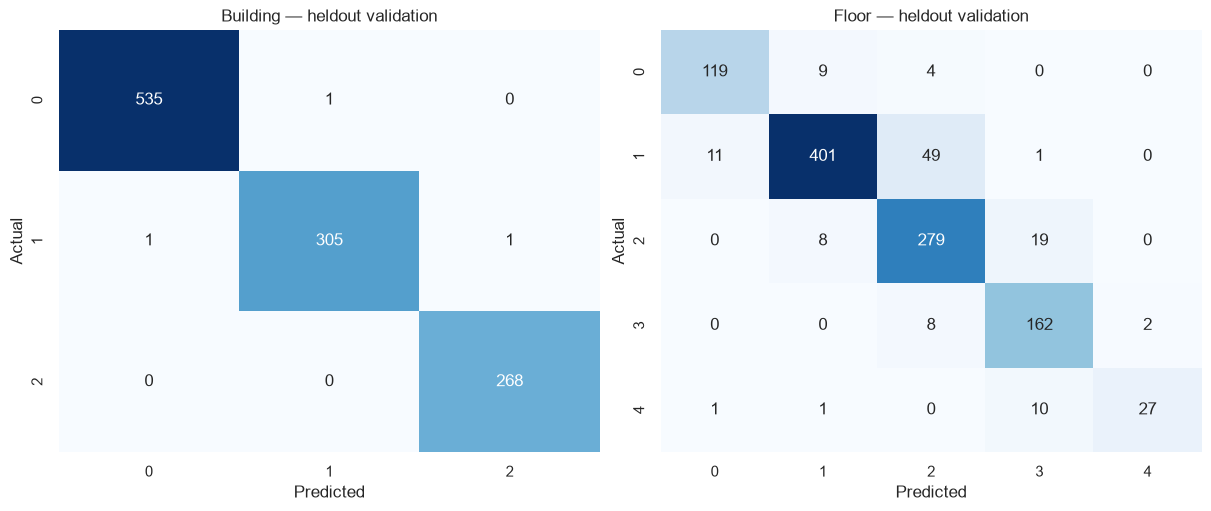

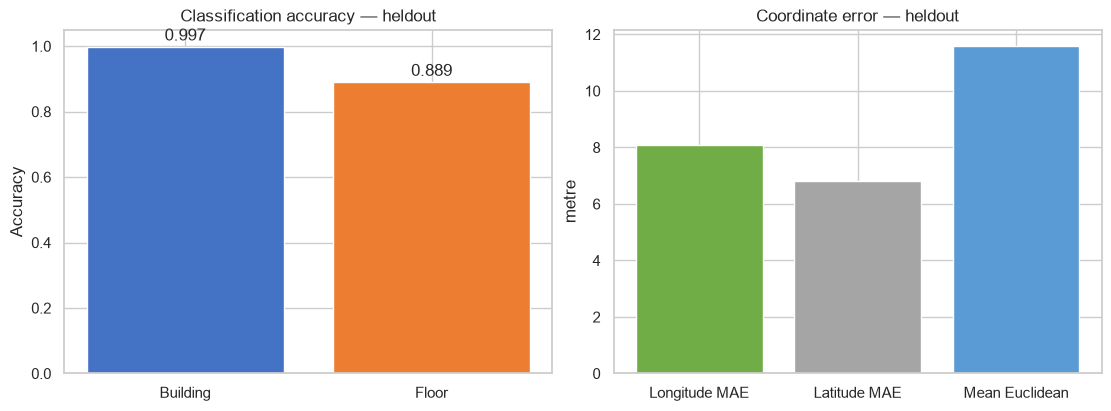

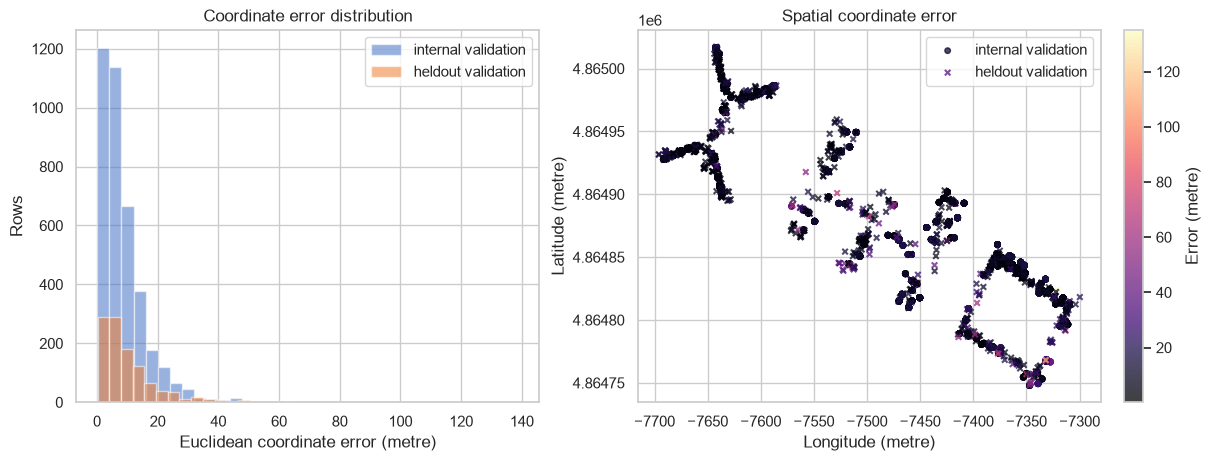

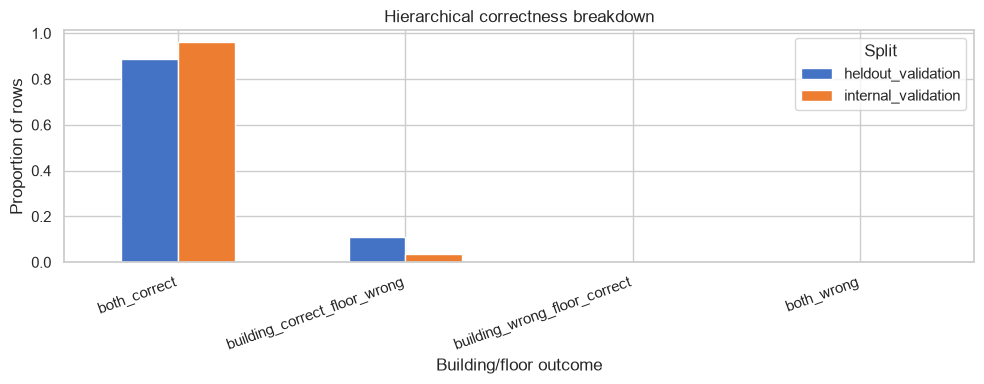

In [10]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, task, truth_col, pred_col, title in [
    (axes[0], 'building', 'BUILDINGID_TRUE', 'BUILDINGID_PRED', 'Building — heldout validation'),
    (axes[1], 'floor', 'FLOOR_TRUE', 'FLOOR_PRED', 'Floor — heldout validation')]:
    df = integrated['heldout_validation']
    labels = sorted(set(df[truth_col]) | set(df[pred_col]))
    cm = confusion_matrix(df[truth_col], df[pred_col], labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=labels, yticklabels=labels)
    ax.set(title=title, xlabel='Predicted', ylabel='Actual')
    pd.DataFrame(cm, index=labels, columns=labels).rename_axis('actual').to_csv(TABLES / f'ml_05_{task}_heldout_confusion_matrix.csv')
fig.savefig(FIGURES / 'ml_05_heldout_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()

held = summary_metrics.query('split == "heldout_validation"').set_index('task')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].bar(['Building', 'Floor'], [held.loc['building','accuracy'], held.loc['floor','accuracy']], color=['#4472C4','#ED7D31'])
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel('Accuracy'); axes[0].set_title('Classification accuracy — heldout')
for i, value in enumerate([held.loc['building','accuracy'], held.loc['floor','accuracy']]): axes[0].text(i, value + .02, f'{value:.3f}', ha='center')
coord_unit = held.loc['coordinate','coordinate_unit']
axes[1].bar(['Longitude MAE','Latitude MAE','Mean Euclidean'], [held.loc['coordinate','mae_longitude'],held.loc['coordinate','mae_latitude'],held.loc['coordinate','mean_euclidean_error']], color=['#70AD47','#A5A5A5','#5B9BD5'])
axes[1].set_ylabel(coord_unit); axes[1].set_title('Coordinate error — heldout')
fig.savefig(FIGURES / 'ml_05_heldout_metric_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for split, color in [('internal_validation','#4472C4'),('heldout_validation','#ED7D31')]:
    df = integrated[split]
    axes[0].hist(df['COORDINATE_ERROR_RECOMPUTED'], bins=35, alpha=.55, label=split.replace('_',' '), color=color)
axes[0].set(xlabel=f'Euclidean coordinate error ({coord_unit})', ylabel='Rows', title='Coordinate error distribution'); axes[0].legend()
for split, marker in [('internal_validation','o'),('heldout_validation','x')]:
    df = integrated[split]
    axes[1].scatter(df['LONGITUDE_TRUE'], df['LATITUDE_TRUE'], c=df['COORDINATE_ERROR_RECOMPUTED'], cmap='magma', s=16, alpha=.75, marker=marker, label=split.replace('_',' '))
axes[1].set(xlabel=f'Longitude ({coord_unit})', ylabel=f'Latitude ({coord_unit})', title='Spatial coordinate error')
axes[1].legend(); fig.colorbar(axes[1].collections[-1], ax=axes[1], label=f'Error ({coord_unit})')
fig.savefig(FIGURES / 'ml_05_coordinate_error_visualizations.png', dpi=160, bbox_inches='tight')
plt.show()

plot_h = hierarchical_breakdown.pivot(index='hierarchy_outcome', columns='split', values='proportion').reindex(['both_correct','building_correct_floor_wrong','building_wrong_floor_correct','both_wrong'])
ax = plot_h.plot(kind='bar', figsize=(10,4), color=['#4472C4','#ED7D31'])
ax.set(ylabel='Proportion of rows', xlabel='Building/floor outcome', title='Hierarchical correctness breakdown'); ax.legend(title='Split'); plt.xticks(rotation=20, ha='right'); plt.tight_layout()
ax.figure.savefig(FIGURES / 'ml_05_hierarchical_error_breakdown.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Export integrated submission artifacts

The following CSVs are written to the existing `data/processed` folder: task metric summary; integrated internal and heldout row-level predictions; hierarchy outcome summary; and actual building-floor group analysis. Four figures and task confusion matrices are also saved there. Final assertions verify the exported row counts and table contents.

**Cell purpose:** Exports integrated tables, verifies their contents, and prints consolidated summaries.


In [11]:
# A concise long-form metric table retains each metric's natural name and unit.
summary_metrics.to_csv(TABLES / 'ml_05_aml_summary_metrics.csv', index=False)
for split, name in [('internal_validation','internal_validation'), ('heldout_validation','heldout')]:
    integrated[split].to_csv(TABLES / f'ml_05_aml_{name}_integrated_predictions.csv', index=False)
hierarchical_breakdown.to_csv(TABLES / 'ml_05_aml_hierarchical_error_breakdown.csv', index=False)
hierarchical_by_location.to_csv(TABLES / 'ml_05_aml_hierarchical_by_building_floor.csv', index=False)

# Round-trip checks ensure the generated artifacts are readable and cover every integrated row.
for split, name in [('internal_validation','internal_validation'), ('heldout_validation','heldout')]:
    exported = pd.read_csv(TABLES / f'ml_05_aml_{name}_integrated_predictions.csv')
    assert len(exported) == len(integrated[split])
    assert not exported.duplicated(KEY).any()
    assert set(map(tuple, exported[KEY].itertuples(index=False, name=None))) == set(map(tuple, integrated[split][KEY].itertuples(index=False, name=None)))
metrics_export = pd.read_csv(TABLES / 'ml_05_aml_summary_metrics.csv')
assert len(metrics_export) == 6 and set(metrics_export['task']) == {'building','floor','coordinate'}
assert hierarchical_breakdown.groupby('split')['n_rows'].sum().to_dict() == {k: len(v) for k,v in integrated.items()}
print('Integrated AML outputs written and verified:')
for path in sorted([ *TABLES.glob('ml_05_*'), *FIGURES.glob('ml_05_*') ]):
    print(f'  {path.name} ({path.stat().st_size:,} bytes)')
print('\nHeldout metric summary:')
print(summary_metrics.query('split == "heldout_validation"').to_string(index=False))
print('\nHierarchical outcomes:')
print(hierarchical_breakdown.to_string(index=False))

Integrated AML outputs written and verified:
  ml_05_coordinate_error_visualizations.png (192,740 bytes)
  ml_05_heldout_confusion_matrices.png (56,907 bytes)
  ml_05_heldout_metric_comparison.png (44,819 bytes)
  ml_05_hierarchical_error_breakdown.png (58,329 bytes)
  ml_05_aml_heldout_integrated_predictions.csv (371,559 bytes)
  ml_05_aml_hierarchical_by_building_floor.csv (3,176 bytes)
  ml_05_aml_hierarchical_error_breakdown.csv (899 bytes)
  ml_05_aml_internal_validation_integrated_predictions.csv (1,256,132 bytes)
  ml_05_aml_summary_metrics.csv (1,226 bytes)
  ml_05_building_heldout_confusion_matrix.csv (43 bytes)
  ml_05_floor_heldout_confusion_matrix.csv (90 bytes)

Heldout metric summary:
             split       task                                                                                               model_config  accuracy  macro_f1  n_rows coordinate_unit  mae_longitude  mae_latitude  mean_euclidean_error  median_euclidean_error
heldout_validation   building       

## 8. Interpretation and scope

The evaluation keeps the internal validation and supplied heldout validation results separate. A correct floor class is counted as a floor match; the joint building-floor measure is the stricter exact hierarchical match. The coordinate head's error is summarized in the EPSG:3857 projected coordinate units recorded by coordinate-regression notebook. This notebook integrates and validates existing outputs; it does not retrain or retune any AML model and does not begin the DL phase.

**How to interpret these scores.** The supplied partition and grouped development split do not guarantee that every Wi-Fi fingerprint is unique across training and evaluation data; repeated two-dimensional coordinate values may also occur. Scores therefore describe performance under the current split and do not establish generalization to unseen fingerprints or unseen positions. The current research question uses the supplied split; adopt a stricter fingerprint- or position-grouped split only if that research question changes.

## Conclusion

This notebook validates row alignment across the three task outputs, recomputes their metrics, and reports hierarchical building-floor outcomes for internal and held-out validation separately. Scores describe the supplied split and should be interpreted with possible fingerprint overlap and repeated two-dimensional coordinates in mind.

## Next Steps

Use the consolidated tables and figures in the Phase 1 AML report and presentation. Keep the split protocol and score limitations visible; begin Phase 2 deep learning only when requested.